# Downloading ERA5 data to use in Ch. 2 project

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import pandas as pd  # library for data analysis for text files (everything but netcdf files)
import xarray as xr #package that open and manipulates netcdf files
import matplotlib.dates as mdates
import numpy.linalg as LA
from matplotlib.gridspec import GridSpec
import timeit
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
import scipy.signal as sig
import scipy.io as sio
from scipy.stats import linregress
from matplotlib.backends.backend_pdf import PdfPages

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from scipy.stats import pearsonr

import matplotlib.patches as mpatches
import time

# Set up API for download

In [68]:
cds_config = """
url: https://cds.climate.copernicus.eu/api
key: 8b28d06f-762d-43bc-960e-7258be38527e
"""

# Write it to the .cdsapirc file in your home directory
with open("/Users/eblckfrd/.cdsapirc", "w") as f:
    f.write(cds_config)

In [70]:
with open("/Users/eblckfrd/.cdsapirc", "r") as f:
    contents = f.read()
print(contents)


url: https://cds.climate.copernicus.eu/api
key: 8b28d06f-762d-43bc-960e-7258be38527e



## Download: Single level monthly average reanalysis: 10m wind speed, top net solar radiation downward, top net thermal radiation downward

In [6]:
import cdsapi

dataset = "reanalysis-era5-single-levels-monthly-means"
request = {
    "product_type": ["monthly_averaged_reanalysis"],
    "variable": [
        "10m_wind_speed",
        "top_net_solar_radiation",
        "top_net_thermal_radiation"
    ],
    "year": [
        "1980", "1981", "1982",
        "1983", "1984", "1985",
        "1986", "1987", "1988",
        "1989", "1990", "1991",
        "1992", "1993", "1994",
        "1995", "1996", "1997",
        "1998", "1999", "2000",
        "2001", "2002", "2003",
        "2004", "2005", "2006",
        "2007", "2008", "2009",
        "2010", "2011", "2012",
        "2013", "2014", "2015",
        "2016", "2017", "2018",
        "2019", "2020"
    ],
    "month": [
        "05", "06", "07",
        "08", "09"
    ],
    "time": ["00:00"],
    "data_format": "netcdf",
    "download_format": "unarchived",
    "area": [51, -100, 39, -82]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()

2025-10-02 14:34:25,070 INFO Request ID is a7acd78a-1b0d-4874-a080-72bd286f92d9
2025-10-02 14:34:25,236 INFO status has been updated to accepted
2025-10-02 14:34:34,054 INFO status has been updated to running
2025-10-02 14:35:42,040 INFO status has been updated to successful


eea67d313607dd91e30a36dd7403b64.zip:   0%|          | 0.00/3.34M [00:00<?, ?B/s]

'eea67d313607dd91e30a36dd7403b64.zip'

In [8]:
import zipfile

zip_path = "eea67d313607dd91e30a36dd7403b64.zip"
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("era5_data")

## Download: Pressure level monthly average reanalysis: geopotential height, u-winds, v-winds at 500mb

Using an expanded boundary for the pressure levels data-- need to capture jet stream and rossby wave behavior

In [81]:
import cdsapi

dataset = "reanalysis-era5-pressure-levels-monthly-means"
request = {
    "product_type": ["monthly_averaged_reanalysis"],
    "variable": [
        "geopotential",
        "u_component_of_wind",
        "v_component_of_wind"
    ],
    "pressure_level": ["500"],
    "year": [
        "1980", "1981", "1982",
        "1983", "1984", "1985",
        "1986", "1987", "1988",
        "1989", "1990", "1991",
        "1992", "1993", "1994",
        "1995", "1996", "1997",
        "1998", "1999", "2000",
        "2001", "2002", "2003",
        "2004", "2005", "2006",
        "2007", "2008", "2009",
        "2010", "2011", "2012",
        "2013", "2014", "2015",
        "2016", "2017", "2018",
        "2019", "2020"
    ],
    "month": [
        "05", "06", "07",
        "08", "09"
    ],
    "time": ["00:00"],
    "data_format": "netcdf",
    "download_format": "unarchived",
    "area": [70, -130, 25, -60]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()

2025-10-07 14:26:46,509 INFO Request ID is c0161436-a107-4612-92c9-5d3c4450cbe8
2025-10-07 14:26:46,691 INFO status has been updated to accepted
2025-10-07 14:27:00,742 INFO status has been updated to running
2025-10-07 14:28:03,246 INFO status has been updated to successful


'c5ba46cd43b3e536dc0079d52b793149.nc'

# Put all data into workable format

In [10]:
import xarray as xr

ds = xr.open_dataset("era5_data/data_stream-moda_stepType-avgua.nc")
print(ds)

#si10 = 10m_wind_speed

<xarray.Dataset> Size: 3MB
Dimensions:     (valid_time: 205, latitude: 49, longitude: 73)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 2kB 1980-05-01 ... 2020-09-01
  * latitude    (latitude) float64 392B 51.0 50.75 50.5 ... 39.5 39.25 39.0
  * longitude   (longitude) float64 584B -100.0 -99.75 -99.5 ... -82.25 -82.0
    expver      (valid_time) <U4 3kB ...
Data variables:
    si10        (valid_time, latitude, longitude) float32 3MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-10-02T19:35 GRIB to CDM+CF via cfgrib-0.9.1...


In [12]:
windspeed = ds.si10
print(windspeed)


<xarray.DataArray 'si10' (valid_time: 205, latitude: 49, longitude: 73)> Size: 3MB
[733285 values with dtype=float32]
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 2kB 1980-05-01 ... 2020-09-01
  * latitude    (latitude) float64 392B 51.0 50.75 50.5 ... 39.5 39.25 39.0
  * longitude   (longitude) float64 584B -100.0 -99.75 -99.5 ... -82.25 -82.0
    expver      (valid_time) <U4 3kB ...
Attributes: (12/32)
    GRIB_paramId:                             207
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      3577
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgua
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               m s**-1
    long_name:                                10 metre wind speed
    units:                   

In [14]:
dp = xr.open_dataset("era5_data/data_stream-moda_stepType-avgad.nc")
print(dp)

#tsr = top net solar radiation
#ttr = top net thermal radiation

<xarray.Dataset> Size: 6MB
Dimensions:     (valid_time: 205, latitude: 49, longitude: 73)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 2kB 1980-05-01T06:00:00 ... 2020-...
  * latitude    (latitude) float64 392B 51.0 50.75 50.5 ... 39.5 39.25 39.0
  * longitude   (longitude) float64 584B -100.0 -99.75 -99.5 ... -82.25 -82.0
    expver      (valid_time) <U4 3kB ...
Data variables:
    tsr         (valid_time, latitude, longitude) float32 3MB ...
    ttr         (valid_time, latitude, longitude) float32 3MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-10-02T19:35 GRIB to CDM+CF via cfgrib-0.9.1...


In [16]:
tsr = dp.tsr
ttr = dp.ttr

#print(tsr)
print(ttr)

<xarray.DataArray 'ttr' (valid_time: 205, latitude: 49, longitude: 73)> Size: 3MB
[733285 values with dtype=float32]
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 2kB 1980-05-01T06:00:00 ... 2020-...
  * latitude    (latitude) float64 392B 51.0 50.75 50.5 ... 39.5 39.25 39.0
  * longitude   (longitude) float64 584B -100.0 -99.75 -99.5 ... -82.25 -82.0
    expver      (valid_time) <U4 3kB ...
Attributes: (12/32)
    GRIB_paramId:                             179
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      3577
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgad
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               J m**-2
    long_name:                                Top net long-wave (thermal) rad...
    unit

In [3]:
dr = xr.open_dataset("c5ba46cd43b3e536dc0079d52b793149.nc")
print(dr)

#z = geopotential height
#u = u-winds
#v = v-winds

<xarray.Dataset> Size: 125MB
Dimensions:         (valid_time: 205, pressure_level: 1, latitude: 181,
                     longitude: 281)
Coordinates:
    number          int64 8B ...
  * valid_time      (valid_time) datetime64[ns] 2kB 1980-05-01 ... 2020-09-01
  * pressure_level  (pressure_level) float64 8B 500.0
  * latitude        (latitude) float64 1kB 70.0 69.75 69.5 ... 25.5 25.25 25.0
  * longitude       (longitude) float64 2kB -130.0 -129.8 ... -60.25 -60.0
    expver          (valid_time) <U4 3kB ...
Data variables:
    z               (valid_time, pressure_level, latitude, longitude) float32 42MB ...
    u               (valid_time, pressure_level, latitude, longitude) float32 42MB ...
    v               (valid_time, pressure_level, latitude, longitude) float32 42MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution

In [102]:
geoheight = dr.z
uwinds = dr.u
vwinds = dr.v

#print(geoheight)
print(uwinds)


<xarray.DataArray 'u' (valid_time: 205, pressure_level: 1, latitude: 181,
                       longitude: 281)> Size: 42MB
[10426505 values with dtype=float32]
Coordinates:
    number          int64 8B ...
  * valid_time      (valid_time) datetime64[ns] 2kB 1980-05-01 ... 2020-09-01
  * pressure_level  (pressure_level) float64 8B 500.0
  * latitude        (latitude) float64 1kB 70.0 69.75 69.5 ... 25.5 25.25 25.0
  * longitude       (longitude) float64 2kB -130.0 -129.8 ... -60.25 -60.0
    expver          (valid_time) <U4 3kB ...
Attributes: (12/31)
    GRIB_paramId:                             131
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      50861
    GRIB_typeOfLevel:                         isobaricInhPa
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgua
    ...                                       ...
    GRIB_shortName:                           u
    GRIB_totalNumber:           

# Trim windspeed, ttr, tsr down to Minnesota using polygon mask, then average seasonally and export as .csv

In [22]:
# 0) Choose a states set that exists across versions
try:
    STATES = regionmask.defined_regions.natural_earth_v5_0_0.us_states_50
except AttributeError:
    STATES = regionmask.defined_regions.natural_earth.us_states_50

mn_idx = [i for i, n in enumerate(STATES.names) if n == "Minnesota"][0]

# 1) Find your lon/lat coord names from the dataset or the windspeed DataArray
def find_coord(da_or_ds, candidates):
    for c in candidates:
        if c in getattr(da_or_ds, "coords", {}):
            return c
        if c in getattr(da_or_ds, "dims", ()):
            return c
    raise KeyError("Could not find any of: " + ", ".join(candidates))

lon_name = find_coord(windspeed, ["longitude", "lon", "x"])
lat_name = find_coord(windspeed, ["latitude", "lat", "y"])

# 2) Get 1-D lon/lat arrays
lon = windspeed[lon_name]
lat = windspeed[lat_name]

# 3) Convert longitudes to [-180, 180)
if float(lon.max()) > 180:
    lon_new = ((lon + 180) % 360) - 180
    order = np.argsort(lon_new)
    lon = lon_new[order]
    windspeed = windspeed.isel({lon_name: order})

# 4) Ensure latitude is monotonic (regionmask handles either asc/desc fine, but be consistent)
# (Optional; usually ERA5 latitude is descending.)

# 5) Build the mask by passing lon/lat explicitly
mask = STATES.mask(lon, lat)  # dims: (lat, lon) but names may be generic

# 6) Align mask coords/names to your DataArray so broadcasting works
mask = mask.rename({mask.dims[0]: lat_name, mask.dims[1]: lon_name})
mask = mask.assign_coords({lat_name: windspeed[lat_name], lon_name: windspeed[lon_name]})

# 7) Apply mask to keep only Minnesota cells
mn_windspeed = windspeed.where(mask == mn_idx, drop=True)
print(mn_windspeed)

<xarray.DataArray 'si10' (valid_time: 205, latitude: 23, longitude: 30)> Size: 566kB
array([[[      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [4.161331 , 4.0578156, 3.888382 , ...,       nan,       nan,
               nan],
        ...,
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan]],

       [[      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [4.338112 , 4.2624283, 4.1530533, ...,       nan,       nan,
               nan],
...
        [      nan,       nan,       nan, ...,       nan,       nan,
               na

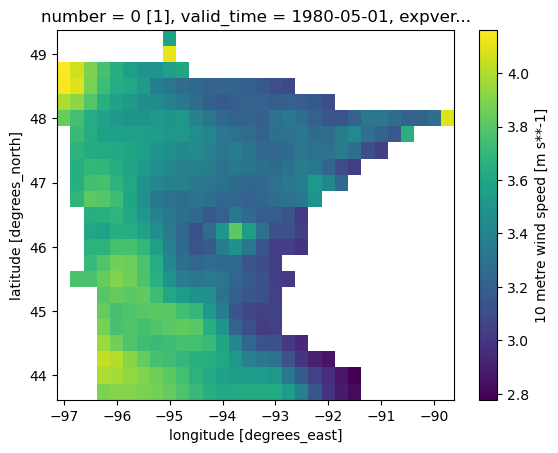

In [24]:
# pick one time slice to test that map worked

mn_windspeed.isel(valid_time=0).plot(cmap="viridis")
plt.show()

In [26]:
#repeat for tsr and ttr

def find_coord(da_or_ds, candidates):
    for c in candidates:
        if c in getattr(da_or_ds, "coords", {}):
            return c
        if c in getattr(da_or_ds, "dims", ()):
            return c
    raise KeyError("Could not find any of: " + ", ".join(candidates))

lon_name = find_coord(tsr, ["longitude", "lon", "x"])
lat_name = find_coord(tsr, ["latitude", "lat", "y"])

lon = tsr[lon_name]
lat = tsr[lat_name]

if float(lon.max()) > 180:
    lon_new = ((lon + 180) % 360) - 180
    order = np.argsort(lon_new)
    lon = lon_new[order]
    tsr = tsr.isel({lon_name: order})

mask = STATES.mask(lon, lat)  # dims: (lat, lon) but names may be generic
mask = mask.rename({mask.dims[0]: lat_name, mask.dims[1]: lon_name})
mask = mask.assign_coords({lat_name: tsr[lat_name], lon_name: tsr[lon_name]})

mn_tsr = tsr.where(mask == mn_idx, drop=True)
print(mn_tsr)


<xarray.DataArray 'tsr' (valid_time: 205, latitude: 23, longitude: 30)> Size: 566kB
array([[[      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [29121536., 28925952., 28935168., ...,       nan,       nan,
               nan],
        ...,
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan]],

       [[      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [29628416., 29390848., 29348864., ...,       nan,       nan,
               nan],
...
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan

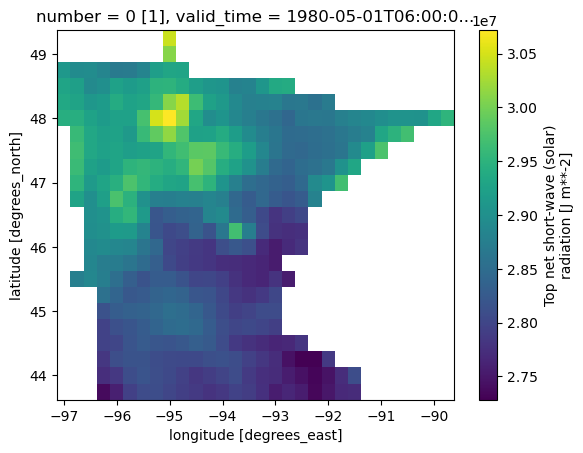

In [28]:
# pick one time slice to test that map worked

mn_tsr.isel(valid_time=0).plot(cmap="viridis")
plt.show()

In [30]:
#now for ttr

def find_coord(da_or_ds, candidates):
    for c in candidates:
        if c in getattr(da_or_ds, "coords", {}):
            return c
        if c in getattr(da_or_ds, "dims", ()):
            return c
    raise KeyError("Could not find any of: " + ", ".join(candidates))

lon_name = find_coord(ttr, ["longitude", "lon", "x"])
lat_name = find_coord(ttr, ["latitude", "lat", "y"])

lon = ttr[lon_name]
lat = ttr[lat_name]

if float(lon.max()) > 180:
    lon_new = ((lon + 180) % 360) - 180
    order = np.argsort(lon_new)
    lon = lon_new[order]
    ttr = ttr.isel({lon_name: order})

mask = STATES.mask(lon, lat)  # dims: (lat, lon) but names may be generic
mask = mask.rename({mask.dims[0]: lat_name, mask.dims[1]: lon_name})
mask = mask.assign_coords({lat_name: ttr[lat_name], lon_name: ttr[lon_name]})

mn_ttr = ttr.where(mask == mn_idx, drop=True)
print(mn_ttr)

<xarray.DataArray 'ttr' (valid_time: 205, latitude: 23, longitude: 30)> Size: 566kB
array([[[       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [-21622528., -21585152., -21500160., ...,        nan,
                nan,        nan],
        ...,
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]],

       [[       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [-21562688., -21525312., -21485376., ...,        nan,
                nan,        nan],
...
        [       nan,        nan, 

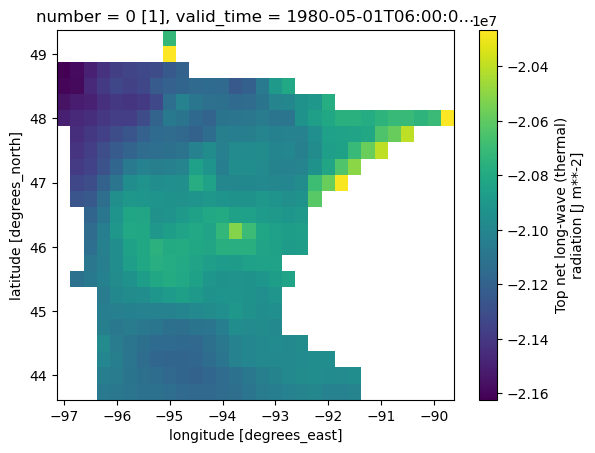

In [32]:
# pick one time slice to test that map worked

mn_ttr.isel(valid_time=0).plot(cmap="viridis")
plt.show()

In [71]:
#combine windspeed, ttr, and tsr data into one dataset

MN_climate1 = xr.merge([
    mn_ttr.rename('ttr'),
    mn_tsr.rename('tsr'),
    mn_windspeed.rename('windspeed')
])

print(MN_climate1)

<xarray.Dataset> Size: 3MB
Dimensions:     (valid_time: 410, latitude: 23, longitude: 30)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 3kB 1980-05-01 ... 2020-09-01T06:...
  * latitude    (latitude) float64 184B 49.25 49.0 48.75 ... 44.25 44.0 43.75
  * longitude   (longitude) float64 240B -97.0 -96.75 -96.5 ... -90.0 -89.75
    number      int64 8B 0
    expver      (valid_time) object 3kB '0001' '0001' '0001' ... '0001' '0001'
Data variables:
    ttr         (valid_time, latitude, longitude) float32 1MB nan nan ... nan
    tsr         (valid_time, latitude, longitude) float32 1MB nan nan ... nan
    windspeed   (valid_time, latitude, longitude) float32 1MB nan nan ... nan
Attributes: (12/32)
    GRIB_paramId:                             179
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      3577
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:               

In [75]:
# Add year and month coordinates for easier grouping
MN_climate1 = MN_climate1.assign_coords(
    year=MN_climate1['valid_time'].dt.year,
    month=MN_climate1['valid_time'].dt.month
)

# Extract specific months/seasons for each variable
# May only (month 5)
may_data = MN_climate1.where(MN_climate1['month'] == 5, drop=True).groupby('year').mean(dim='valid_time')

# May-June average (months 5-6)
may_june_data = MN_climate1.where(MN_climate1['month'].isin([5, 6]), drop=True).groupby('year').mean(dim='valid_time')

# August only (month 8)
august_data = MN_climate1.where(MN_climate1['month'] == 8, drop=True).groupby('year').mean(dim='valid_time')

# July-August-September average (months 7-8-9)
jas_data = MN_climate1.where(MN_climate1['month'].isin([7, 8, 9]), drop=True).groupby('year').mean(dim='valid_time')


In [77]:
# Combine all into one dataset with clear naming
final_ds = xr.Dataset({
    'ttr_may': may_data['ttr'],
    'ttr_may_june': may_june_data['ttr'],
    'ttr_august': august_data['ttr'],
    'ttr_jas': jas_data['ttr'],
    'tsr_may': may_data['tsr'],
    'tsr_may_june': may_june_data['tsr'],
    'tsr_august': august_data['tsr'],
    'tsr_jas': jas_data['tsr'],
    'windspeed_may': may_data['windspeed'],
    'windspeed_may_june': may_june_data['windspeed'],
    'windspeed_august': august_data['windspeed'],
    'windspeed_jas': jas_data['windspeed']
})

# Check the results
print("Final dataset structure:")
print(final_ds)

Final dataset structure:
<xarray.Dataset> Size: 1MB
Dimensions:             (latitude: 23, longitude: 30, year: 41)
Coordinates:
  * latitude            (latitude) float64 184B 49.25 49.0 48.75 ... 44.0 43.75
  * longitude           (longitude) float64 240B -97.0 -96.75 ... -90.0 -89.75
    number              int64 8B 0
  * year                (year) int64 328B 1980 1981 1982 1983 ... 2018 2019 2020
Data variables:
    ttr_may             (year, latitude, longitude) float32 113kB nan ... nan
    ttr_may_june        (year, latitude, longitude) float32 113kB nan ... nan
    ttr_august          (year, latitude, longitude) float32 113kB nan ... nan
    ttr_jas             (year, latitude, longitude) float32 113kB nan ... nan
    tsr_may             (year, latitude, longitude) float32 113kB nan ... nan
    tsr_may_june        (year, latitude, longitude) float32 113kB nan ... nan
    tsr_august          (year, latitude, longitude) float32 113kB nan ... nan
    tsr_jas             (year, lat

In [79]:
# Convert to DataFrame and drop NaNs
df = final_ds.to_dataframe().reset_index()
df_clean = df.dropna(subset=['ttr_may', 'ttr_may_june', 'ttr_august', 'ttr_jas',
                               'tsr_may', 'tsr_may_june', 'tsr_august', 'tsr_jas',
                               'windspeed_may', 'windspeed_may_june', 'windspeed_august', 'windspeed_jas'], 
                      how='any')

print(f"\nOriginal size: {len(df)} rows")
print(f"After removing NaNs: {len(df_clean)} rows")
print(f"Rows removed: {len(df) - len(df_clean)}")


Original size: 28290 rows
After removing NaNs: 16072 rows
Rows removed: 12218


In [83]:
# Preview the cleaned data
print("\nFirst few rows:")
print(df_clean.head())


First few rows:
     latitude  longitude  year  number     ttr_may  ttr_may_june  ttr_august  \
328     49.25      -95.0  1980       0 -20721920.0   -20819744.0 -21014192.0   
329     49.25      -95.0  1981       0 -19813840.0   -20020872.0 -21947552.0   
330     49.25      -95.0  1982       0 -19231472.0   -19927000.0 -21726464.0   
331     49.25      -95.0  1983       0 -19534352.0   -19942160.0 -22766416.0   
332     49.25      -95.0  1984       0 -19588400.0   -19944680.0 -22931984.0   

        ttr_jas     tsr_may  tsr_may_june  tsr_august     tsr_jas  \
328 -20814480.0  30437376.0    30429696.0  23366656.0  23692742.0   
329 -21835690.0  28833792.0    28572160.0  24773632.0  24571958.0   
330 -20977242.0  25367552.0    27320320.0  25276416.0  23952240.0   
331 -21631274.0  28316672.0    28433920.0  26635264.0  24653018.0   
332 -21548934.0  28529664.0    28424704.0  26590208.0  24798570.0   

     windspeed_may  windspeed_may_june  windspeed_august  windspeed_jas  
328       3.5

In [93]:
#now export to switch over to R

df_clean.to_csv('MN_seasonalclimate.csv', index=False)

# Now work with pressure level data

# Look at maps of climatology for may and june data

In [104]:
#calculate climatology each month using groupby
climo = geoheight.groupby('valid_time.month').mean('valid_time') 
climo2 = uwinds.groupby('valid_time.month').mean('valid_time') 
climo3 = vwinds.groupby('valid_time.month').mean('valid_time') 

In [105]:
#group the original data by month and remove each month's climatological mean
norm_geoheight = geoheight.groupby('valid_time.month')-climo
norm_uwinds = uwinds.groupby('valid_time.month')-climo2
norm_vwinds = vwinds.groupby('valid_time.month')-climo3

In [106]:
#isolate month of May and June
may_hgt = norm_geoheight.sel(valid_time=norm_geoheight.valid_time.dt.month == 5)
june_hgt = norm_geoheight.sel(valid_time=norm_geoheight.valid_time.dt.month == 6)

may_uwinds = norm_uwinds.sel(valid_time=norm_uwinds.valid_time.dt.month == 5)
june_uwinds = norm_uwinds.sel(valid_time=norm_uwinds.valid_time.dt.month == 6)

may_vwinds = norm_vwinds.sel(valid_time=norm_vwinds.valid_time.dt.month == 5)
june_vwinds = norm_vwinds.sel(valid_time=norm_vwinds.valid_time.dt.month == 6)

In [110]:
may_hgt = may_hgt[:, 0, :, :]
june_hgt = june_hgt[:, 0, :, :]

may_uwinds = may_uwinds[:, 0, :, :]
june_uwinds = june_uwinds[:, 0, :, :]

may_vwinds = may_vwinds[:, 0, :, :]
june_vwinds = june_vwinds [:, 0, :, :]

In [112]:
print(june_vwinds)

<xarray.DataArray 'v' (valid_time: 41, latitude: 181, longitude: 281)> Size: 8MB
array([[[ 2.6741982e-01,  1.7113316e-01,  8.0562949e-02, ...,
          4.3172598e+00,  4.4028759e+00,  4.4846334e+00],
        [ 2.9011893e-01,  1.9109309e-01,  9.6056938e-02, ...,
          4.1196012e+00,  4.1970358e+00,  4.2718735e+00],
        [ 3.0819750e-01,  2.0450294e-01,  1.0461974e-01, ...,
          3.9354599e+00,  4.0047960e+00,  4.0731907e+00],
        ...,
        [ 3.2127559e+00,  3.1639516e+00,  3.1206851e+00, ...,
          3.4402337e-02,  2.7363941e-02,  3.9308965e-02],
        [ 3.0226717e+00,  2.9799173e+00,  2.9430342e+00, ...,
          3.7001669e-03,  3.3428818e-03,  1.6669393e-02],
        [ 2.8388755e+00,  2.8073516e+00,  2.7733862e+00, ...,
         -2.3214854e-02, -3.1122625e-02, -3.2242104e-02]],

       [[ 2.9783630e-01,  2.7381527e-01,  2.4672163e-01, ...,
         -2.5893352e+00, -2.6487389e+00, -2.7105360e+00],
        [ 2.8440261e-01,  2.5129473e-01,  2.1534061e-01, ...,
  

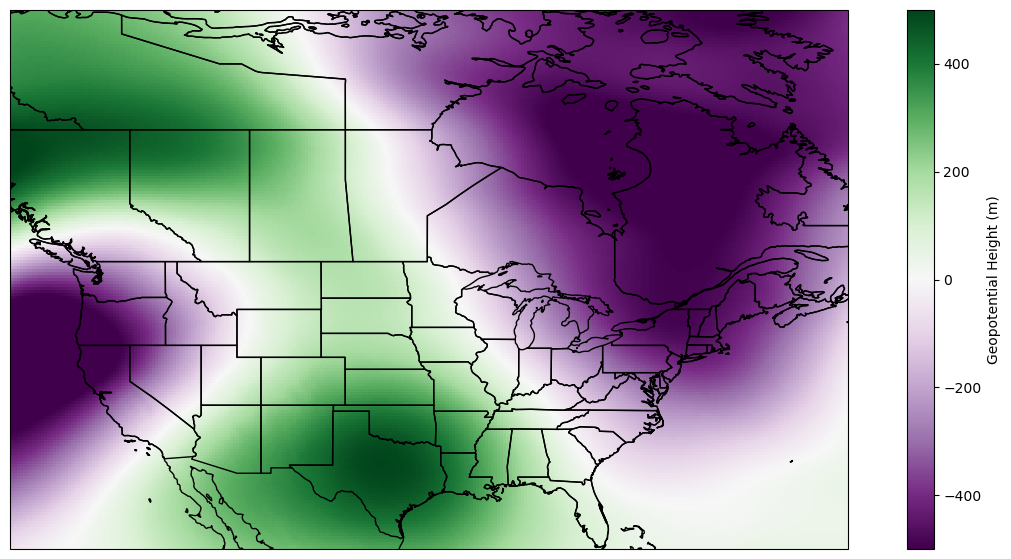

In [120]:
#GEO HEIGHT MAP: just look at first time step to see if data is showing up

june_hgt_2d = june_hgt[0, :, :]

f = plt.figure(figsize=(15,7))
ax = plt.subplot(projection=ccrs.PlateCarree())
CS = plt.pcolormesh(lon, lat, june_hgt_2d,  # Use the 2D slice
                    cmap=plt.cm.PRGn, 
                    vmin=-500, vmax=500, 
                    transform=ccrs.PlateCarree())
plt.xlabel('Longitude')
plt.ylabel('Latitude')
ax.coastlines()
ax.set_extent([-130, -60, 25, 70], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES)
cb = plt.colorbar(CS, ax=ax)
cb.set_label('Geopotential Height (m)')
plt.show()

In [122]:
vmin = np.nanmin(june_uwinds)
vmax = np.nanmax(june_uwinds)

print(f"vmin: {vmin}")
print(f"vmax: {vmax}")

vmin: -11.183053016662598
vmax: 11.040528297424316


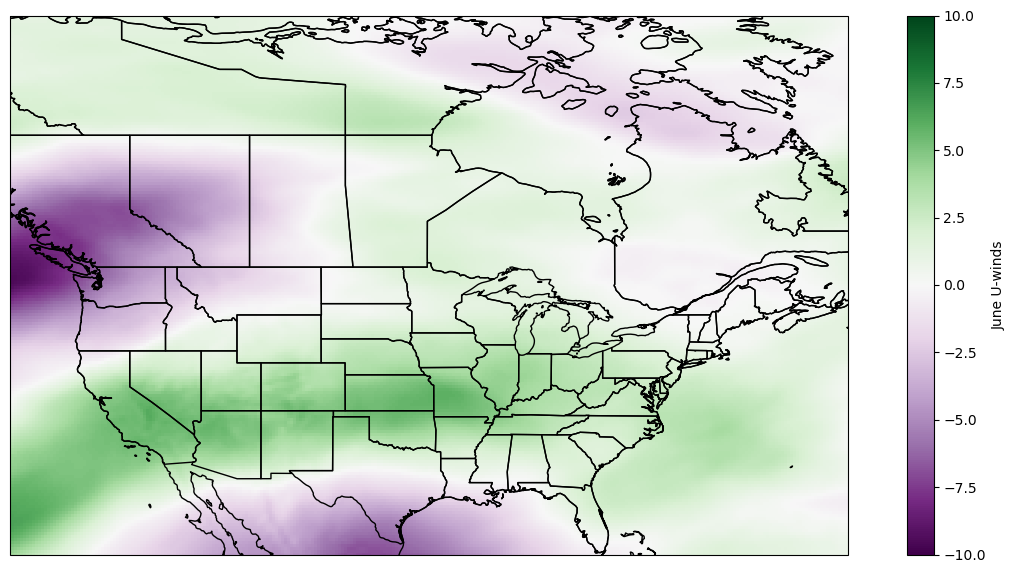

In [126]:
#WIND MAP: just look at first time step to see if data is showing up

june_uwinds_2d = june_uwinds[0, :, :]

f = plt.figure(figsize=(15,7))
ax = plt.subplot(projection=ccrs.PlateCarree())
CS = plt.pcolormesh(lon, lat, june_uwinds_2d,  # Use the 2D slice
                    cmap=plt.cm.PRGn, 
                    vmin=-10, vmax=10, 
                    transform=ccrs.PlateCarree())
plt.xlabel('Longitude')
plt.ylabel('Latitude')
ax.coastlines()
ax.set_extent([-130, -60, 25, 70], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES)
cb = plt.colorbar(CS, ax=ax)
cb.set_label('June U-winds')
plt.show()

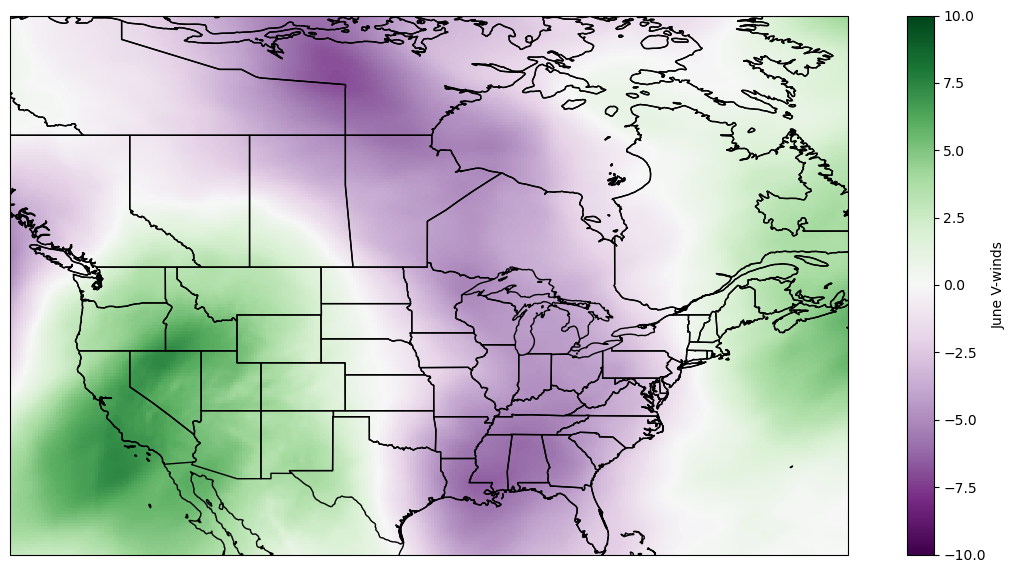

In [128]:
june_vwinds_2d = june_vwinds[0, :, :]

f = plt.figure(figsize=(15,7))
ax = plt.subplot(projection=ccrs.PlateCarree())
CS = plt.pcolormesh(lon, lat, june_vwinds_2d,  # Use the 2D slice
                    cmap=plt.cm.PRGn, 
                    vmin=-10, vmax=10, 
                    transform=ccrs.PlateCarree())
plt.xlabel('Longitude')
plt.ylabel('Latitude')
ax.coastlines()
ax.set_extent([-130, -60, 25, 70], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES)
cb = plt.colorbar(CS, ax=ax)
cb.set_label('June V-winds')
plt.show()

# Bring in VHT, lat, lon, and lagosid from all lakes (done in R), then find significant geopotential height correlation grids

In [25]:
# COARSEN the geopotential height grid (0.25° → 1° resolution)
#I dont need so much detail when just looking for teleconnection patterns

june_hgt_coarse = june_hgt.coarsen(latitude=4, longitude=4, boundary='trim').mean()
print(f"Original shape: {june_hgt.shape}")
print(f"Coarsened shape: {june_hgt_coarse.shape}")

Original shape: (41, 181, 281)
Coarsened shape: (41, 45, 70)


In [29]:
# Load lake data (JAS conditions)
lake_df = pd.read_csv('lake_VHT.csv')

# Extract years
years = june_hgt_coarse.valid_time.dt.year.values

lake_pivot = lake_df.pivot(
    index='year',
    columns='lagoslakeid',
    values='VHT'
)

In [31]:
#this is just for validation, years should be 1980-2020

#Find common years between geopotential and lakes
common_years = np.intersect1d(
    june_hgt_coarse.valid_time.dt.year.values,
    lake_pivot.index.values
)

# Subset to common years
june_hgt_common = june_hgt_coarse.sel(
    valid_time=june_hgt_coarse.valid_time.dt.year.isin(common_years)
)
lake_pivot_common = lake_pivot.loc[common_years]

print(f"Using {len(common_years)} common years: {common_years.min()}-{common_years.max()}")

Using 41 common years: 1980-2020


In [33]:
# Count how many years each lake has (non-NaN values)
lake_completeness = lake_pivot_common.notna().sum().sort_values(ascending=False)

print(f"\nTotal lakes: {len(lake_completeness)}")
print(f"Lakes with complete data: {(lake_completeness == len(common_years)).sum()}")

# Select top 25 most complete lakes
N_lakes_to_use = 25
top_lakes = lake_completeness.head(N_lakes_to_use).index

# Subset lake data
lake_pivot_subset = lake_pivot_common[top_lakes]
lake_array = lake_pivot_subset.values  # (n_years, 25 lakes)

print(f"\nUsing top {N_lakes_to_use} most complete lakes")


Total lakes: 357
Lakes with complete data: 0

Using top 25 most complete lakes


In [35]:
# Get dimensions
n_years = len(common_years)
n_lat = len(june_hgt_common.latitude)
n_lon = len(june_hgt_common.longitude)
n_lakes = lake_array.shape[1]

print(f"\nGrid dimensions: {n_lat} lat × {n_lon} lon = {n_lat * n_lon} grid points")
print(f"Total correlations: {n_lat * n_lon * n_lakes:,}")
print("\nEstimated time: 2-3 minutes...\n")

# Reshape geopotential height to (n_years, n_gridpoints)
hgt_reshaped = june_hgt_common.values.reshape(n_years, -1)

# Initialize output arrays
avg_correlation = np.zeros(n_lat * n_lon)
max_correlation = np.zeros(n_lat * n_lon)
significant_count = np.zeros(n_lat * n_lon)


Grid dimensions: 45 lat × 70 lon = 3150 grid points
Total correlations: 78,750

Estimated time: 2-3 minutes...



In [39]:
start_time = time.time()
print("Calculating correlations...")

for grid_idx in range(n_lat * n_lon):
    hgt_timeseries = hgt_reshaped[:, grid_idx]
    
    # Skip if NaN
    if np.isnan(hgt_timeseries).any():
        avg_correlation[grid_idx] = np.nan
        max_correlation[grid_idx] = np.nan
        continue
    
    correlations = []
    
    # Correlate with all lakes
    for lake_idx in range(n_lakes):
        lake_timeseries = lake_array[:, lake_idx]
        
        # Skip lakes with too many NaNs
        valid_mask = ~np.isnan(lake_timeseries)
        if valid_mask.sum() < 10:
            continue
        
        try:
            corr, pval = pearsonr(
                hgt_timeseries[valid_mask],
                lake_timeseries[valid_mask]
            )
            correlations.append(abs(corr))
            
            if pval < 0.05:
                significant_count[grid_idx] += 1
        except:
            continue
    
    if len(correlations) > 0:
        avg_correlation[grid_idx] = np.mean(correlations)
        max_correlation[grid_idx] = np.max(correlations)

Calculating correlations...


In [41]:
# Reshape back to 2D
avg_correlation = avg_correlation.reshape(n_lat, n_lon)
max_correlation = max_correlation.reshape(n_lat, n_lon)
significant_count = significant_count.reshape(n_lat, n_lon)

elapsed = time.time() - start_time
print(f"\n✓ Completed in {elapsed:.1f} seconds ({elapsed/60:.1f} minutes)!")
print(f"\nCorrelation statistics:")
print(f"  Mean correlation: {np.nanmean(avg_correlation):.3f}")
print(f"  Max correlation: {np.nanmax(avg_correlation):.3f}")
print(f"  Min correlation: {np.nanmin(avg_correlation):.3f}")


✓ Completed in 72.3 seconds (1.2 minutes)!

Correlation statistics:
  Mean correlation: 0.150
  Max correlation: 0.260
  Min correlation: 0.080


In [59]:
# Find grid points with highest average correlation
threshold = np.nanpercentile(avg_correlation, 95)  # Top 5%
high_corr_mask = avg_correlation > threshold

print(f"\n=== HIGH CORRELATION REGIONS ===")
print(f"Threshold (90th percentile): {threshold:.3f}")
print(f"Number of high-correlation grid points: {high_corr_mask.sum()}")

# Get coordinates of high correlation points
high_corr_lats = []
high_corr_lons = []
for i in range(n_lat):
    for j in range(n_lon):
        if high_corr_mask[i, j]:
            high_corr_lats.append(june_hgt_common.latitude.values[i])
            high_corr_lons.append(june_hgt_common.longitude.values[j])

if len(high_corr_lats) > 0:
    print(f"\nHigh correlation region center:")
    print(f"  Latitude: {np.mean(high_corr_lats):.2f}° ({np.min(high_corr_lats):.2f} to {np.max(high_corr_lats):.2f})")
    print(f"  Longitude: {np.mean(high_corr_lons):.2f}° ({np.min(high_corr_lons):.2f} to {np.max(high_corr_lons):.2f})")


=== HIGH CORRELATION REGIONS ===
Threshold (90th percentile): 0.219
Number of high-correlation grid points: 158

High correlation region center:
  Latitude: 54.71° (49.62 to 59.62)
  Longitude: -86.23° (-96.62 to -76.62)


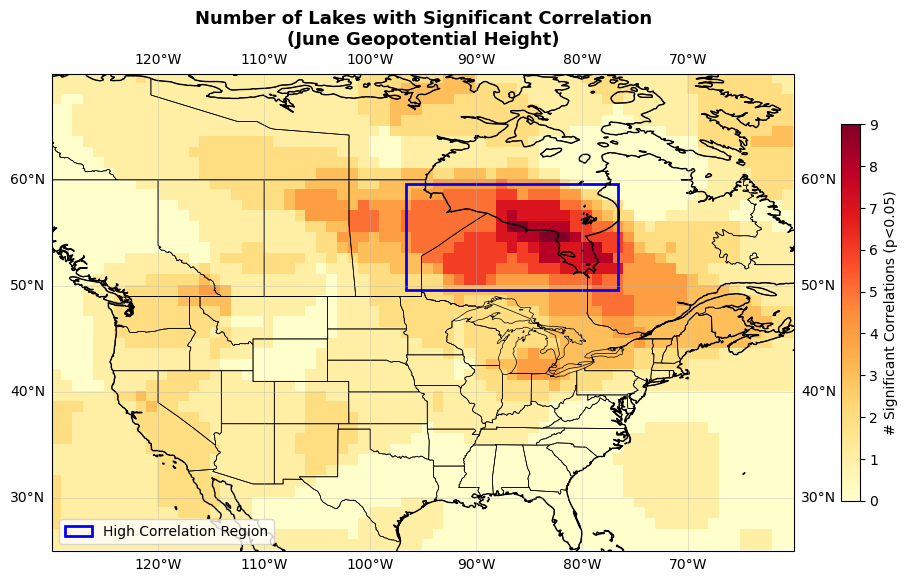

In [61]:
# Create a new figure and axes with the projection
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={'projection': ccrs.PlateCarree()})

# Store the pcolormesh return value
pcm = ax.pcolormesh(june_hgt_common.longitude, june_hgt_common.latitude,
                    significant_count, cmap='YlOrRd', 
                    transform=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.set_extent([-130, -60, 25, 70], crs=ccrs.PlateCarree())
ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)

# Add box around high correlation region
if len(high_corr_lats) > 0:
    min_lon = np.min(high_corr_lons)
    max_lon = np.max(high_corr_lons)
    min_lat = np.min(high_corr_lats)
    max_lat = np.max(high_corr_lats)
    
    # Create rectangle
    rect = mpatches.Rectangle((min_lon, min_lat), 
                               max_lon - min_lon, 
                               max_lat - min_lat,
                               linewidth=2, 
                               edgecolor='blue', 
                               facecolor='none',
                               transform=ccrs.PlateCarree(),
                               label='High Correlation Region')
    ax.add_patch(rect)
    ax.legend(loc='lower left')

# Use fig.colorbar with the pcm object
fig.colorbar(pcm, ax=ax, label='# Significant Correlations (p<0.05)', shrink=0.7)
ax.set_title('Number of Lakes with Significant Correlation\n(June Geopotential Height)', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## NOW repeat this for may data (Did not get good results-- not physically accurate)

In [68]:
# COARSEN the geopotential height grid (0.25° → 1° resolution)
#I dont need so much detail when just looking for teleconnection patterns

may_hgt_coarse = may_hgt.coarsen(latitude=4, longitude=4, boundary='trim').mean()
print(f"Original shape: {may_hgt.shape}")
print(f"Coarsened shape: {may_hgt_coarse.shape}")

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Original shape: (41, 181, 281)
Coarsened shape: (41, 45, 70)


In [72]:
# Extract years
years = may_hgt_coarse.valid_time.dt.year.values

#this is just for validation, years should be 1980-2020

#Find common years between geopotential and lakes
common_years = np.intersect1d(
    may_hgt_coarse.valid_time.dt.year.values,
    lake_pivot.index.values
)

# Subset to common years
may_hgt_common = may_hgt_coarse.sel(
    valid_time=may_hgt_coarse.valid_time.dt.year.isin(common_years)
)
lake_pivot_common = lake_pivot.loc[common_years]

print(f"Using {len(common_years)} common years: {common_years.min()}-{common_years.max()}")

# Get dimensions
n_years = len(common_years)
n_lat = len(may_hgt_common.latitude)
n_lon = len(may_hgt_common.longitude)
n_lakes = lake_array.shape[1]

print(f"\nGrid dimensions: {n_lat} lat × {n_lon} lon = {n_lat * n_lon} grid points")
print(f"Total correlations: {n_lat * n_lon * n_lakes:,}")

# Reshape geopotential height to (n_years, n_gridpoints)
hgt_reshaped = may_hgt_common.values.reshape(n_years, -1)

# Initialize output arrays
avg_correlation = np.zeros(n_lat * n_lon)
max_correlation = np.zeros(n_lat * n_lon)
significant_count = np.zeros(n_lat * n_lon)


Using 41 common years: 1980-2020

Grid dimensions: 45 lat × 70 lon = 3150 grid points
Total correlations: 78,750


In [74]:
start_time = time.time()
print("Calculating correlations...")

for grid_idx in range(n_lat * n_lon):
    hgt_timeseries = hgt_reshaped[:, grid_idx]
    
    # Skip if NaN
    if np.isnan(hgt_timeseries).any():
        avg_correlation[grid_idx] = np.nan
        max_correlation[grid_idx] = np.nan
        continue
    
    correlations = []
    
    # Correlate with all lakes
    for lake_idx in range(n_lakes):
        lake_timeseries = lake_array[:, lake_idx]
        
        # Skip lakes with too many NaNs
        valid_mask = ~np.isnan(lake_timeseries)
        if valid_mask.sum() < 10:
            continue
        
        try:
            corr, pval = pearsonr(
                hgt_timeseries[valid_mask],
                lake_timeseries[valid_mask]
            )
            correlations.append(abs(corr))
            
            if pval < 0.05:
                significant_count[grid_idx] += 1
        except:
            continue
    
    if len(correlations) > 0:
        avg_correlation[grid_idx] = np.mean(correlations)
        max_correlation[grid_idx] = np.max(correlations)

Calculating correlations...


In [76]:
# Reshape back to 2D
avg_correlation = avg_correlation.reshape(n_lat, n_lon)
max_correlation = max_correlation.reshape(n_lat, n_lon)
significant_count = significant_count.reshape(n_lat, n_lon)

elapsed = time.time() - start_time
print(f"\n✓ Completed in {elapsed:.1f} seconds ({elapsed/60:.1f} minutes)!")
print(f"\nCorrelation statistics:")
print(f"  Mean correlation: {np.nanmean(avg_correlation):.3f}")
print(f"  Max correlation: {np.nanmax(avg_correlation):.3f}")
print(f"  Min correlation: {np.nanmin(avg_correlation):.3f}")


✓ Completed in 55.9 seconds (0.9 minutes)!

Correlation statistics:
  Mean correlation: 0.166
  Max correlation: 0.235
  Min correlation: 0.105


In [78]:
# Find grid points with highest average correlation
threshold = np.nanpercentile(avg_correlation, 95)  # Top 5%
high_corr_mask = avg_correlation > threshold

print(f"\n=== HIGH CORRELATION REGIONS ===")
print(f"Threshold (90th percentile): {threshold:.3f}")
print(f"Number of high-correlation grid points: {high_corr_mask.sum()}")

# Get coordinates of high correlation points
high_corr_lats = []
high_corr_lons = []
for i in range(n_lat):
    for j in range(n_lon):
        if high_corr_mask[i, j]:
            high_corr_lats.append(may_hgt_common.latitude.values[i])
            high_corr_lons.append(may_hgt_common.longitude.values[j])

if len(high_corr_lats) > 0:
    print(f"\nHigh correlation region center:")
    print(f"  Latitude: {np.mean(high_corr_lats):.2f}° ({np.min(high_corr_lats):.2f} to {np.max(high_corr_lats):.2f})")
    print(f"  Longitude: {np.mean(high_corr_lons):.2f}° ({np.min(high_corr_lons):.2f} to {np.max(high_corr_lons):.2f})")


=== HIGH CORRELATION REGIONS ===
Threshold (90th percentile): 0.217
Number of high-correlation grid points: 158

High correlation region center:
  Latitude: 62.51° (34.62 to 68.62)
  Longitude: -111.64° (-129.62 to -103.62)


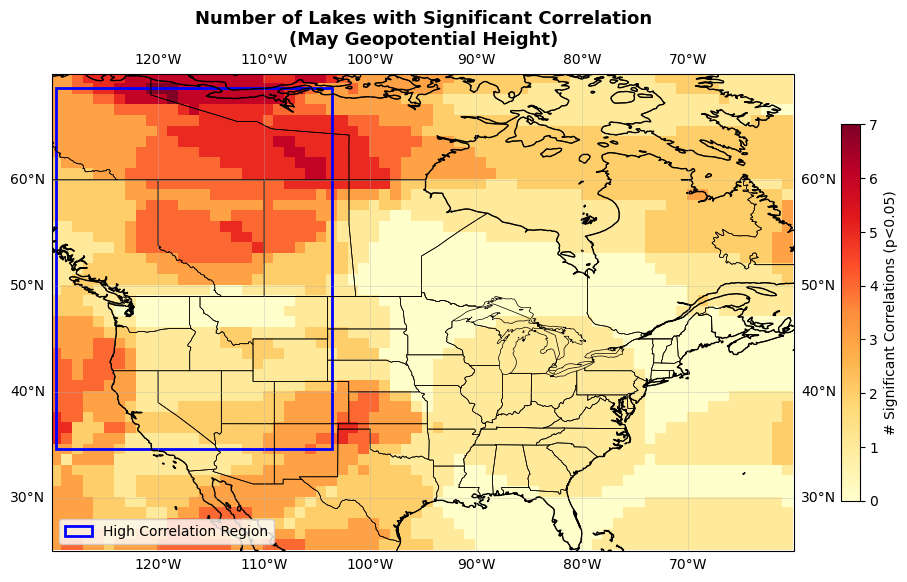

In [80]:
# Create a new figure and axes with the projection
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={'projection': ccrs.PlateCarree()})

# Store the pcolormesh return value
pcm = ax.pcolormesh(may_hgt_common.longitude, may_hgt_common.latitude,
                    significant_count, cmap='YlOrRd', 
                    transform=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.set_extent([-130, -60, 25, 70], crs=ccrs.PlateCarree())
ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)

# Add box around high correlation region
if len(high_corr_lats) > 0:
    min_lon = np.min(high_corr_lons)
    max_lon = np.max(high_corr_lons)
    min_lat = np.min(high_corr_lats)
    max_lat = np.max(high_corr_lats)
    
    # Create rectangle
    rect = mpatches.Rectangle((min_lon, min_lat), 
                               max_lon - min_lon, 
                               max_lat - min_lat,
                               linewidth=2, 
                               edgecolor='blue', 
                               facecolor='none',
                               transform=ccrs.PlateCarree(),
                               label='High Correlation Region')
    ax.add_patch(rect)
    ax.legend(loc='lower left')

# Use fig.colorbar with the pcm object
fig.colorbar(pcm, ax=ax, label='# Significant Correlations (p<0.05)', shrink=0.7)
ax.set_title('Number of Lakes with Significant Correlation\n(May Geopotential Height)', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [133]:
#NEED TO CHECK IF THIS IS NEGATIVE OR POSITIVE GEO HEIGHT?

# Repeat this process for June v-winds

In [130]:
# COARSEN grid (0.25° → 1° resolution)
#I dont need so much detail when just looking for teleconnection patterns

june_vwinds_coarse = june_vwinds.coarsen(latitude=4, longitude=4, boundary='trim').mean()
print(f"Original shape: {june_vwinds.shape}")
print(f"Coarsened shape: {june_vwinds_coarse.shape}")

Original shape: (41, 181, 281)
Coarsened shape: (41, 45, 70)


In [135]:
# Extract years
years = june_vwinds_coarse.valid_time.dt.year.values

#this is just for validation, years should be 1980-2020

#Find common years between geopotential and lakes
common_years = np.intersect1d(
    june_vwinds_coarse.valid_time.dt.year.values,
    lake_pivot.index.values
)

# Subset to common years
june_vwinds_common = june_vwinds_coarse.sel(
    valid_time=june_vwinds_coarse.valid_time.dt.year.isin(common_years)
)
lake_pivot_common = lake_pivot.loc[common_years]

print(f"Using {len(common_years)} common years: {common_years.min()}-{common_years.max()}")

# Get dimensions
n_years = len(common_years)
n_lat = len(june_vwinds_common.latitude)
n_lon = len(june_vwinds_common.longitude)
n_lakes = lake_array.shape[1]

print(f"\nGrid dimensions: {n_lat} lat × {n_lon} lon = {n_lat * n_lon} grid points")
print(f"Total correlations: {n_lat * n_lon * n_lakes:,}")

# Reshape geopotential height to (n_years, n_gridpoints)
vwinds_reshaped = june_vwinds_common.values.reshape(n_years, -1)

# Initialize output arrays
avg_correlation = np.zeros(n_lat * n_lon)
max_correlation = np.zeros(n_lat * n_lon)
significant_count = np.zeros(n_lat * n_lon)

Using 41 common years: 1980-2020

Grid dimensions: 45 lat × 70 lon = 3150 grid points
Total correlations: 78,750


In [137]:
start_time = time.time()
print("Calculating correlations...")

for grid_idx in range(n_lat * n_lon):
    vwinds_timeseries = vwinds_reshaped[:, grid_idx]
    
    # Skip if NaN
    if np.isnan(vwinds_timeseries).any():
        avg_correlation[grid_idx] = np.nan
        max_correlation[grid_idx] = np.nan
        continue
    
    correlations = []
    
    # Correlate with all lakes
    for lake_idx in range(n_lakes):
        lake_timeseries = lake_array[:, lake_idx]
        
        # Skip lakes with too many NaNs
        valid_mask = ~np.isnan(lake_timeseries)
        if valid_mask.sum() < 10:
            continue
        
        try:
            corr, pval = pearsonr(
                vwinds_timeseries[valid_mask],
                lake_timeseries[valid_mask]
            )
            correlations.append(abs(corr))
            
            if pval < 0.05:
                significant_count[grid_idx] += 1
        except:
            continue
    
    if len(correlations) > 0:
        avg_correlation[grid_idx] = np.mean(correlations)
        max_correlation[grid_idx] = np.max(correlations)

Calculating correlations...


In [139]:
# Reshape back to 2D
avg_correlation = avg_correlation.reshape(n_lat, n_lon)
max_correlation = max_correlation.reshape(n_lat, n_lon)
significant_count = significant_count.reshape(n_lat, n_lon)

elapsed = time.time() - start_time
print(f"\n✓ Completed in {elapsed:.1f} seconds ({elapsed/60:.1f} minutes)!")
print(f"\nCorrelation statistics:")
print(f"  Mean correlation: {np.nanmean(avg_correlation):.3f}")
print(f"  Max correlation: {np.nanmax(avg_correlation):.3f}")
print(f"  Min correlation: {np.nanmin(avg_correlation):.3f}")


✓ Completed in 48.8 seconds (0.8 minutes)!

Correlation statistics:
  Mean correlation: 0.154
  Max correlation: 0.228
  Min correlation: 0.089


In [141]:
# Find grid points with highest average correlation
threshold = np.nanpercentile(avg_correlation, 95)  # Top 5%
high_corr_mask = avg_correlation > threshold

print(f"\n=== HIGH CORRELATION REGIONS ===")
print(f"Threshold (90th percentile): {threshold:.3f}")
print(f"Number of high-correlation grid points: {high_corr_mask.sum()}")

# Get coordinates of high correlation points
high_corr_lats = []
high_corr_lons = []
for i in range(n_lat):
    for j in range(n_lon):
        if high_corr_mask[i, j]:
            high_corr_lats.append(june_vwinds_common.latitude.values[i])
            high_corr_lons.append(june_vwinds_common.longitude.values[j])

if len(high_corr_lats) > 0:
    print(f"\nHigh correlation region center:")
    print(f"  Latitude: {np.mean(high_corr_lats):.2f}° ({np.min(high_corr_lats):.2f} to {np.max(high_corr_lats):.2f})")
    print(f"  Longitude: {np.mean(high_corr_lons):.2f}° ({np.min(high_corr_lons):.2f} to {np.max(high_corr_lons):.2f})")


=== HIGH CORRELATION REGIONS ===
Threshold (90th percentile): 0.201
Number of high-correlation grid points: 158

High correlation region center:
  Latitude: 54.26° (48.62 to 58.62)
  Longitude: -89.35° (-107.62 to -60.62)


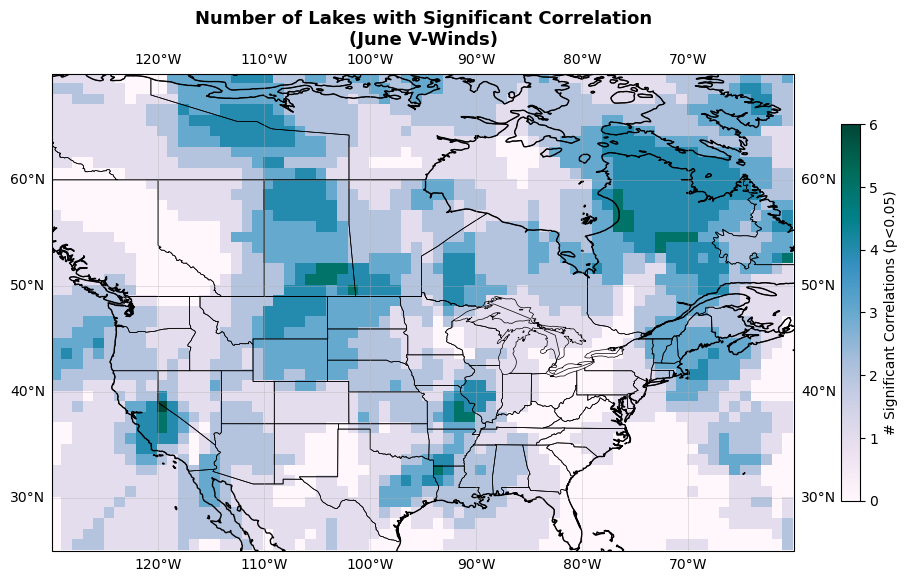

In [149]:
# Create a new figure and axes with the projection
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={'projection': ccrs.PlateCarree()})

# Store the pcolormesh return value
pcm = ax.pcolormesh(june_vwinds_common.longitude, june_vwinds_common.latitude,
                    significant_count, cmap='PuBuGn', 
                    transform=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.set_extent([-130, -60, 25, 70], crs=ccrs.PlateCarree())
ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)

# Add box around high correlation region
#if len(high_corr_lats) > 0:
#    min_lon = np.min(high_corr_lons)
#    max_lon = np.max(high_corr_lons)
#    min_lat = np.min(high_corr_lats)
#    max_lat = np.max(high_corr_lats)
    
    # Create rectangle
#    rect = mpatches.Rectangle((min_lon, min_lat), 
#                               max_lon - min_lon, 
 #                              max_lat - min_lat,
  #                             linewidth=2, 
   #                            edgecolor='blue', 
    #                           facecolor='none',
     #                          transform=ccrs.PlateCarree(),
      #                         label='High Correlation Region')
#    ax.add_patch(rect)
#    ax.legend(loc='lower left')

# Use fig.colorbar with the pcm object
fig.colorbar(pcm, ax=ax, label='# Significant Correlations (p<0.05)', shrink=0.7)
ax.set_title('Number of Lakes with Significant Correlation\n(June V-Winds)', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()